## Imports

In [1]:
import sys

sys.path.append("../")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from docplex.mp.model import Model
from qiskit.circuit import Parameter, QuantumCircuit, QuantumRegister
from qiskit.primitives import BackendEstimatorV2, StatevectorEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.quantum_info import SparsePauliOp
from qiskit_addon_opt_mapper.converters import OptimizationProblemToQubo
from qiskit_addon_opt_mapper.translators import from_docplex_mp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime import QiskitRuntimeService
from tqdm import tqdm

from dicke_state_ansatz import DickeStateAnsatz
from utils import plot_hamiltonian_expval_heatmap, plot_hamiltonian_expval_surface

/home/jvictor/coding/python/quantum-optimization-dicke-states/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sns.set_theme()

In [3]:
with open(file="../../secrets/credentials.json", mode="rt") as f:
    credentials = json.load(f)

In [4]:
service = QiskitRuntimeService(**credentials)

qiskit_runtime_service._discover_account:WARNING:2026-06-05 21:26:13,388: Loading account with the given token. A saved account will not be used.


In [5]:
statevec_estimator = StatevectorEstimator()
noiseless_sim = AerSimulator(method="statevector", device="CPU")
pm = generate_preset_pass_manager(backend=noiseless_sim, optimization_level=0)

In [6]:
assets_data = pd.read_csv(filepath_or_buffer="../datasets/sp500_assets_close_price.csv", index_col=0)

# Estimator Precision

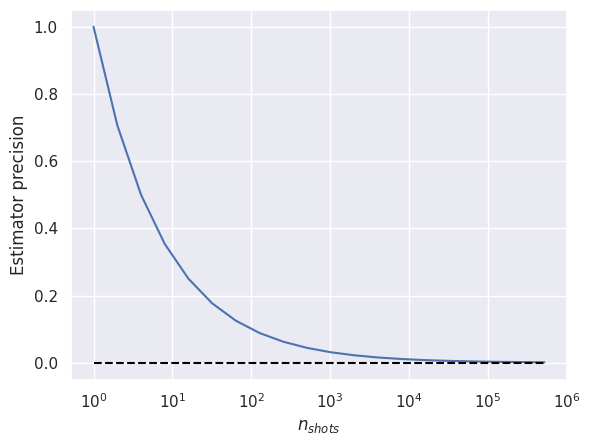

In [69]:
fig, ax = plt.subplots()

ax.plot([2**i for i in range(20)], [1/np.sqrt(2**i) for i in range(20)])
ax.hlines(y=0, xmin=2**0, xmax=2**19, color="black", linestyle="--")
ax.set_xlabel(r"$n_{shots}$")
ax.set_ylabel(r"Estimator precision")
ax.set_xscale("log")

plt.show()

# Pure state

In [8]:
np.random.seed(seed=42)
tickers = np.random.choice(assets_data.columns, size=3, replace=False)

In [9]:
assets_close_price = assets_data[tickers]

In [10]:
assets_pct_change = assets_close_price.pct_change().dropna()

In [11]:
covariance_annualized = assets_pct_change.cov()*np.sqrt(252)
returns_annualized = assets_pct_change.mean()*252

In [12]:
q = 0.5
b = 1
return_risk_free = 0.0375
weights_array = np.array([1/b for _ in range(assets_close_price.columns.shape[0])])

In [13]:
model = Model(name="combinatorial_portfolio_optimization")
x = np.array([model.binary_var(name=f"x({i})") for i in range(len(tickers))])
model.minimize(q*((x*weights_array).T@covariance_annualized.values@(x*weights_array))-(1-q)*(returns_annualized.values@(x*weights_array))+return_risk_free)
model.add_constraint(x.sum() == b)
print(model.prettyprint())

// This file has been generated by DOcplex
// model name is: combinatorial_portfolio_optimization
// single vars section
dvar bool x(0);
dvar bool x(1);
dvar bool x(2);

minimize
 - 0.073237 x(0) + 0.006494 x(1) - 0.050421 x(2) [ 0.005641 x(0)^2
 - 0.000466 x(0)*x(1) + 0.000173 x(0)*x(2) + 0.001649 x(1)^2
 + 0.000596 x(1)*x(2) + 0.001870 x(2)^2 ] + 0.037500;
 
subject to {
 x(0) + x(1) + x(2) == 1;

}
None


In [14]:
result = model.solve()

In [15]:
result.objective_value

-0.030096636453820262

In [16]:
result_array = np.array([result.get_value(f"x({i})") for i in range(assets_close_price.columns.shape[0])])

In [17]:
result_array

array([1., 0., 0.])

In [18]:
quad_model = from_docplex_mp(model=model)
qubo_converter = OptimizationProblemToQubo(penalty=1e-12)
qubo = qubo_converter.convert(quad_model)
ising, offset = qubo.to_ising()

In [19]:
qc = DickeStateAnsatz().generate_quantum_circuit(n=len(tickers), k=b, measurement=False)

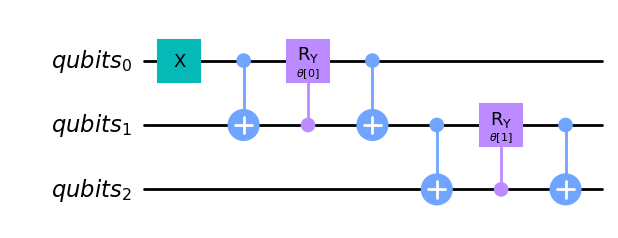

In [20]:
qc.draw(output="mpl", style="clifford")

In [21]:
theta0 = np.linspace(0, 2*np.pi, 101)
theta1 = np.linspace(0, 2*np.pi, 101)
pubs = [
    (qc, ising, (angle0, angle1))
    for angle0 in theta0 for angle1 in theta1
]

## StatevectorEstimator

In [22]:
estimator_job = statevec_estimator.run(pubs=pubs)
estimator_result = estimator_job.result()

In [23]:
expvals = np.array([estimator_result[i].data.evs + offset for i in range(len(pubs))])
expvals = expvals.reshape((101, 101))

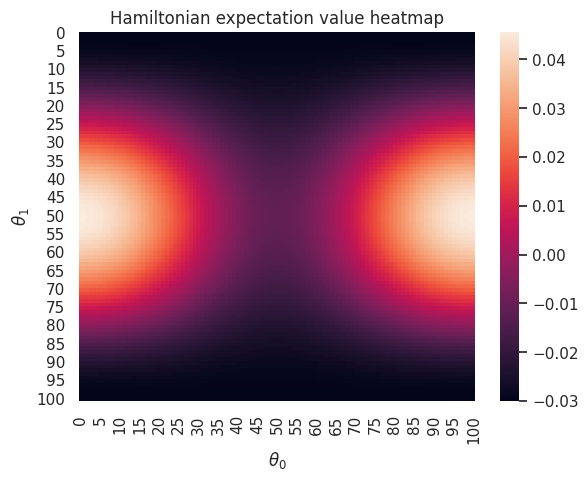

In [24]:
plot_hamiltonian_expval_heatmap(data=expvals)

In [25]:
fig = plot_hamiltonian_expval_surface(x=theta0, y=theta1, z=expvals)
fig.show(renderer="notebook")

## BackendEstimatorV2 - Noiseless simulator

In [26]:
expvals_dict = {}

for n_shots in tqdm([2**i for i in range(13)]):

    noiseless_estimator = BackendEstimatorV2(backend=noiseless_sim, options=dict(default_precision=1/np.sqrt(n_shots)))
    estimator_job = noiseless_estimator.run(pubs=pubs)
    estimator_result = estimator_job.result()
    expvals = np.array([estimator_result[i].data.evs + offset for i in range(len(pubs))])
    expvals = expvals.reshape((101, 101))
    expvals_dict[n_shots] = expvals

100%|██████████| 13/13 [01:24<00:00,  6.49s/it]


In [27]:
n_shots = 256

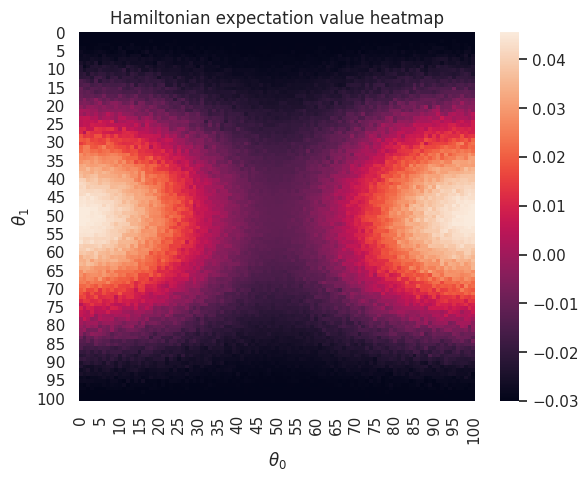

In [28]:
plot_hamiltonian_expval_heatmap(data=expvals_dict[n_shots])

In [29]:
plot_hamiltonian_expval_surface(x=theta0, y=theta1, z=expvals_dict[n_shots])

## BackendEstimatorV2 - Noisy simulator 

In [30]:
backend = service.backend(name="ibm_kingston")
noise_model = NoiseModel.from_backend(backend=backend)
noisy_sim = AerSimulator(method="statevector", device="CPU", noise_model=noise_model)
noisy_estimator = BackendEstimatorV2(backend=noisy_sim, options=dict(default_precision=1/np.sqrt(4096)))

In [31]:
estimator_job = noisy_estimator.run(pubs=pubs)
estimator_result = estimator_job.result()

In [32]:
expvals = np.array([estimator_result[i].data.evs + offset for i in range(len(pubs))])
expvals = expvals.reshape((101, 101))

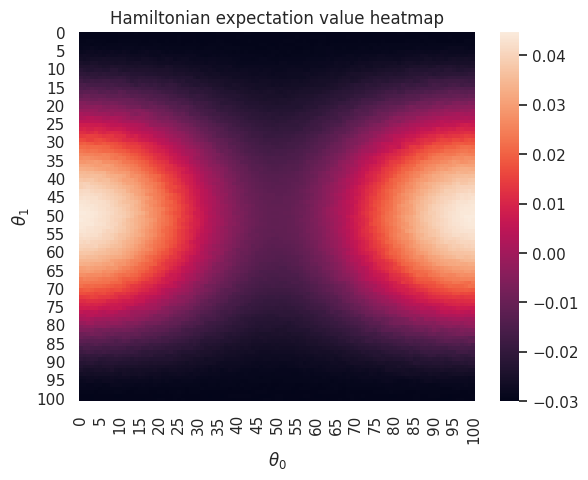

In [33]:
plot_hamiltonian_expval_heatmap(data=expvals)

In [34]:
plot_hamiltonian_expval_surface(x=theta0, y=theta1, z=expvals)

# Mixture

In [35]:
np.random.seed(seed=42)
tickers = np.random.choice(assets_data.columns, size=2, replace=False)

In [36]:
assets_close_price = assets_data[tickers]

In [37]:
assets_pct_change = assets_close_price.pct_change().dropna()

In [38]:
covariance_annualized = assets_pct_change.cov()*np.sqrt(252)
returns_annualized = assets_pct_change.mean()*252

In [39]:
q = 0.5
b = 2
return_risk_free = 0.0375
weights_array = np.ones(shape=(b,))

In [40]:
model = Model(name="combinatorial_portfolio_optimization")
x = np.array([model.binary_var(name=f"x({i})") for i in range(len(tickers))])
model.minimize(q*((x*weights_array).T@covariance_annualized.values@(x*weights_array))-(1-q)*(returns_annualized.values@(x*weights_array))+return_risk_free)
model.add_constraint(x.sum() <= b)
print(model.prettyprint())

// This file has been generated by DOcplex
// model name is: combinatorial_portfolio_optimization
// single vars section
dvar bool x(0);
dvar bool x(1);

minimize
 - 0.073237 x(0) + 0.006494 x(1) [ 0.005641 x(0)^2 - 0.000466 x(0)*x(1)
 + 0.001649 x(1)^2 ] + 0.037500;
 
subject to {
 x(0) + x(1) <= 2;

}
None


In [41]:
result = model.solve()

In [42]:
result.objective_value

-0.030096636453820262

In [43]:
result_array = np.array([result.get_value(f"x({i})") for i in range(assets_close_price.columns.shape[0])])

In [44]:
result_array

array([1., 0.])

In [45]:
model = Model(name="combinatorial_portfolio_optimization")
x = np.array([model.binary_var(name=f"x({i})") for i in range(len(tickers))])
model.minimize(q*((x*weights_array).T@covariance_annualized.values@(x*weights_array))-(1-q)*(returns_annualized.values@(x*weights_array))+return_risk_free)

In [46]:
quad_model = from_docplex_mp(model=model)
qubo_converter = OptimizationProblemToQubo(penalty=1e-12)
qubo = qubo_converter.convert(quad_model)
ising, offset = qubo.to_ising()

In [47]:
identity = SparsePauliOp(data="I", coeffs=[1])
ising_expanded = ising.tensor(other=identity)

In [48]:
n = ising.num_qubits
qubits = QuantumRegister(size=3, name="q")
gamma = Parameter(name=r"$\gamma$")


qc = QuantumCircuit(qubits)
qc.ry(theta=gamma, qubit=qubits[0])

params_names = {1: "alpha", 2: "beta"}

for k in range(1,3):
    dicke = DickeStateAnsatz().generate_quantum_circuit(n=n, k=k, measurement=False, param_name=params_names[k])
    if k == 1:
        qc.x(qubit=qubits[0])
    dicke_gate = dicke.to_gate(label=rf"$\vert D^{n}_{k} \rangle$").control(1)
    qc.append(dicke_gate, qargs=range(qubits.size))
    if k == 1:
        qc.x(qubit=qubits[0])

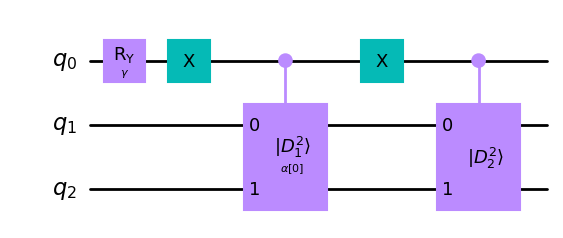

In [49]:
qc.draw(output="mpl", style="clifford")

In [50]:
qc = pm.run(circuits=qc)

In [51]:
gamma = np.linspace(0, 2*np.pi, 101)
alpha = np.linspace(0, 2*np.pi, 101)
pubs = [
    (qc, ising_expanded, (angle0, angle1))
    for angle0 in gamma for angle1 in alpha
]

## StatevectorEstimator

In [52]:
estimator_job = statevec_estimator.run(pubs=pubs)
estimator_result = estimator_job.result()

In [53]:
expvals = np.array([estimator_result[i].data.evs + offset for i in range(len(pubs))])
expvals = expvals.reshape((101, 101))

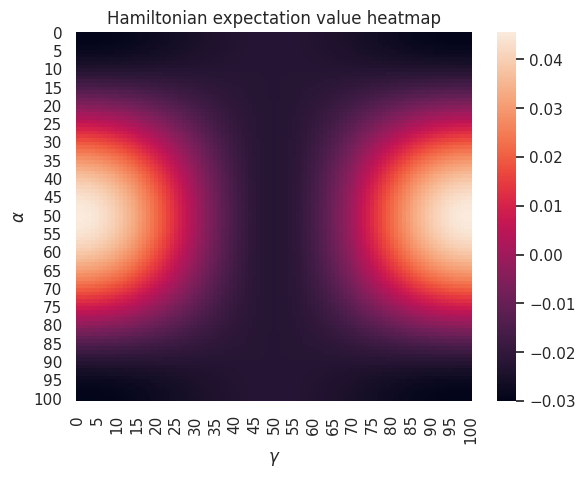

In [54]:
plot_hamiltonian_expval_heatmap(data=expvals, xlabel=r"$\gamma$", ylabel=r"$\alpha$")

In [55]:
plot_hamiltonian_expval_surface(x=gamma, y=alpha, z=expvals, xlabel="gamma", ylabel="alpha")

## BackendEstimatorV2 - Noiseless simulator

In [56]:
expvals_dict = {}

for n_shots in tqdm([2**i for i in range(13)]):

    noiseless_estimator = BackendEstimatorV2(backend=noiseless_sim, options=dict(default_precision=1/np.sqrt(n_shots)))
    estimator_job = noiseless_estimator.run(pubs=pubs)
    estimator_result = estimator_job.result()
    expvals = np.array([estimator_result[i].data.evs + offset for i in range(len(pubs))])
    expvals = expvals.reshape((101, 101))
    expvals_dict[n_shots] = expvals

100%|██████████| 13/13 [01:26<00:00,  6.69s/it]


In [57]:
n_shots = 256

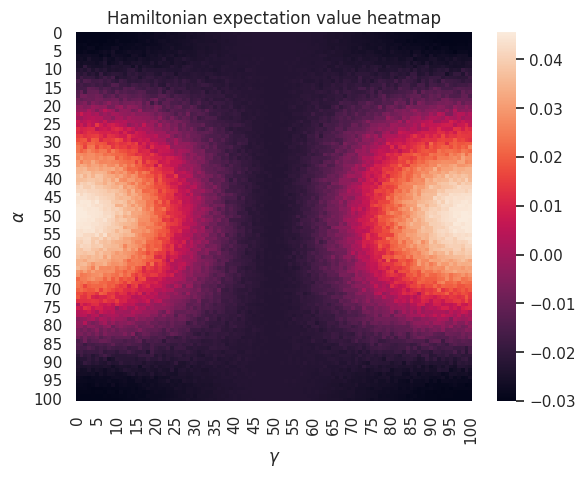

In [58]:
plot_hamiltonian_expval_heatmap(data=expvals_dict[n_shots], xlabel=r"$\gamma$", ylabel=r"$\alpha$")

In [59]:
plot_hamiltonian_expval_surface(x=gamma, y=alpha, z=expvals_dict[n_shots], xlabel="gamma", ylabel="alpha")

## BackendEstimatorV2 - Noisy simulator

In [60]:
backend = service.backend(name="ibm_kingston")
noise_model = NoiseModel.from_backend(backend=backend)
noisy_sim = AerSimulator(method="statevector", device="CPU", noise_model=noise_model)
noisy_estimator = BackendEstimatorV2(backend=noisy_sim, options=dict(default_precision=1/np.sqrt(4096)))

In [61]:
estimator_job = noisy_estimator.run(pubs=pubs)
estimator_result = estimator_job.result()

In [62]:
expvals = np.array([estimator_result[i].data.evs + offset for i in range(len(pubs))])
expvals = expvals.reshape((101, 101))

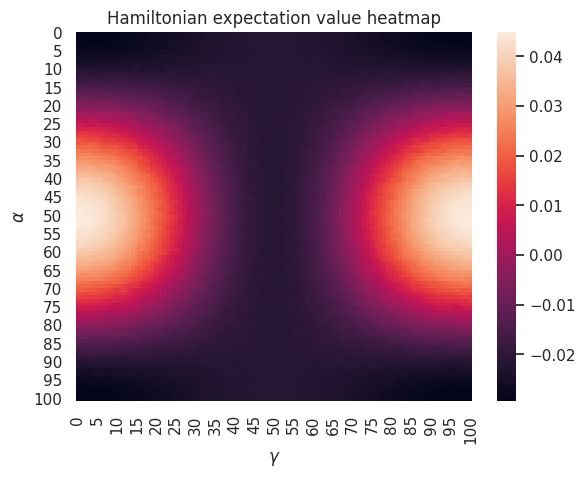

In [63]:
plot_hamiltonian_expval_heatmap(data=expvals, xlabel=r"$\gamma$", ylabel=r"$\alpha$")

In [64]:
plot_hamiltonian_expval_surface(x=gamma, y=alpha, z=expvals, xlabel="gamma", ylabel="alpha")